In [ ]:
# Paths come from config.sh at the repo root (override via the environment).
import os, subprocess, sys


def _cfg(name):
    val = os.environ.get(name)
    if val:
        return val
    root = os.path.abspath(os.getcwd())          # notebooks have no __file__
    while not os.path.isfile(os.path.join(root, "config.sh")) \
            and root != os.path.dirname(root):
        root = os.path.dirname(root)
    val = subprocess.check_output(
        ["bash", "-c", f'source "$1" 2>/dev/null; printf "%s" "${{{name}}}"',
         "_", os.path.join(root, "config.sh")], text=True)
    if not val:
        raise SystemExit(f"ERROR: {name} is not set in the environment or in config.sh")
    return val


PROJ_ROOT = _cfg("PROJ_ROOT")


In [102]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import numpy as np
import matplotlib.pyplot as plt


In [103]:
import plotly
print(plotly.__version__)  # Should print the version (e.g., 5.18.0)

5.18.0


In [104]:
gff_octDeg1=pd.read_csv(f"{PROJ_ROOT}/data/OctDegus1_genome/OctDeg1/genes/GCF_000260255.1_OctDeg1.0_genomic.gff", sep='\t', comment="#", header=None, names=["seqid", "source", "type", "start", "end", "score", "strand", "phase", "attributes"])
gff_dn=pd.read_csv(f"{PROJ_ROOT}/code/command-line-script/genome-annotation/peaks2utr/braker-peaks2utrRun-2samples-7000PFC-181dHIP-gff/braker_peak2utr.gff3", sep='\t', comment="#", header=None, names=["seqid", "source", "type", "start", "end", "score", "strand", "phase", "attributes"])
gff_lo=pd.read_csv(f"{PROJ_ROOT}/output/outputs-from-liftoff/hifiasm-041425-scaffolded-chrAssigned-mito/hifiasm-041425-scaffolded-chrAssigned-mito.gff", sep='\t', comment="#", header=None, names=["seqid", "source", "type", "start", "end", "score", "strand", "phase", "attributes"])
gff_final=pd.read_csv(_cfg("FINAL_ANNOTATION_GFF"), sep='\t', comment="#", header=None, names=["seqid", "source", "type", "start", "end", "score", "strand", "phase", "attributes"])
# gff_final=pd.read_csv("/tscc/projects/ps-renlab2/jhc103/degu-genome-assembly-proj/code/jupyter-notebook-script/gff-build/gff-final/hifiasm_041425_denovoEnhanced_sorted.gff", sep='\t', comment="#", header=None, names=["seqid", "source", "type", "start", "end", "score", "strand", "phase", "attributes"])

gff_octDeg1

,seqid,source,type,start,end,score,strand,phase,attributes
0,NW_004524577.1,RefSeq,region,1,41204401,.,+,.,ID=NW_004524577.1:1..41204401;Dbxref=taxon:101...
1,NW_004524577.1,Gnomon,gene,39668,60375,.,+,.,ID=gene-LOC101559722;Dbxref=GeneID:101559722;N...
2,NW_004524577.1,Gnomon,mRNA,39668,60375,.,+,.,ID=rna-XM_004622867.2;Parent=gene-LOC101559722...
3,NW_004524577.1,Gnomon,exon,39668,39862,.,+,.,ID=exon-XM_004622867.2-1;Parent=rna-XM_0046228...
4,NW_004524577.1,Gnomon,exon,42464,42674,.,+,.,ID=exon-XM_004622867.2-2;Parent=rna-XM_0046228...
...,...,...,...,...,...,...,...,...,...
1151528,NC_020661.1,RefSeq,exon,15331,15397,.,+,.,ID=exon-NC_020661.1:15331..15397-1;Parent=rna-...
1151529,NC_020661.1,RefSeq,tRNA,15404,15469,.,-,.,ID=rna-NC_020661.1:15404..15469;gbkey=tRNA;pro...
1151530,NC_020661.1,RefSeq,exon,15404,15469,.,-,.,ID=exon-NC_020661.1:15404..15469-1;Parent=rna-...
1151531,NC_020661.1,RefSeq,D_loop,15470,16776,.,+,.,ID=id-NC_020661.1:15470..16776;gbkey=D-loop


## Octdeg1

In [105]:
gff_octDeg1['biotype'] = gff_octDeg1['attributes'].str.extract(r'gene_biotype=([^;]+)', expand=False)
gff_octDeg1['biotype'] = gff_octDeg1['biotype'].ffill()

gff_octDeg1['gene_name'] = gff_octDeg1['attributes'].str.extract(r'ID=gene-([^;]+)', expand=False)
# gff_octDeg1['gene_name'] = gff_octDeg1['gene_name'].ffill()


gff_octDeg1['is_LOC_gene'] = np.where(
    gff_octDeg1['gene_name'].str.match(r'^LOC\d{9}$', na=False),
    'LOC genes',
    'Annotated genes'
)

not_na_mask=gff_octDeg1['gene_name'].notna()
# Create boolean mask for duplicated gene names (including all duplicates)
duplicate_mask = not_na_mask & gff_octDeg1['gene_name'].duplicated(keep="first")
# Initialize the column
gff_octDeg1.loc[not_na_mask,'duplicated_status'] = 'Unique'  # Default value for all genes
# Update only the duplicated genes
gff_octDeg1.loc[duplicate_mask, 'duplicated_status'] = 'Ortholog/Duplicate'


## Just to drop the first row 
gff_octDeg1=gff_octDeg1[~gff_octDeg1["gene_name"].isna()]
# ## Filter for level 2 features:
# level2_types = ["tRNA","guide_RNA","C_gene_segment","transcript","V_gene_segment","snoRNA","mRNA","snRNA","lnc_RNA","rRNA"]
# gff_octDeg1 

/tscc/lustre/ddn/scratch/jhc103/temp-dir-fast/ipykernel_1104888/1292872865.py:18: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'Unique' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.



In [106]:
gff_octDeg1

,seqid,source,type,start,end,score,strand,phase,attributes,biotype,gene_name,is_LOC_gene,duplicated_status
1,NW_004524577.1,Gnomon,gene,39668,60375,.,+,.,ID=gene-LOC101559722;Dbxref=GeneID:101559722;N...,protein_coding,LOC101559722,LOC genes,Unique
29,NW_004524577.1,Gnomon,gene,66066,71415,.,-,.,ID=gene-Thumpd1;Dbxref=GeneID:101560112;Name=T...,protein_coding,Thumpd1,Annotated genes,Unique
39,NW_004524577.1,Gnomon,pseudogene,83241,84849,.,+,.,ID=gene-LOC101574413;Dbxref=GeneID:101574413;N...,pseudogene,LOC101574413,LOC genes,Unique
41,NW_004524577.1,Gnomon,gene,111454,180531,.,+,.,ID=gene-LOC101574813;Dbxref=GeneID:101574813;N...,protein_coding,LOC101574813,LOC genes,Unique
70,NW_004524577.1,Gnomon,gene,152489,154926,.,+,.,ID=gene-LOC111815888;Dbxref=GeneID:111815888;N...,lncRNA,LOC111815888,LOC genes,Unique
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1151499,NC_020661.1,RefSeq,gene,9897,10193,.,+,.,ID=gene-ND4L;Dbxref=GeneID:14864913;Name=ND4L;...,protein_coding,ND4L,Annotated genes,Unique
1151503,NC_020661.1,RefSeq,gene,10187,11564,.,+,.,ID=gene-ND4;Dbxref=GeneID:14864917;Name=ND4;gb...,protein_coding,ND4,Annotated genes,Unique
1151513,NC_020661.1,RefSeq,gene,11774,13585,.,+,.,ID=gene-ND5;Dbxref=GeneID:14864918;Name=ND5;gb...,protein_coding,ND5,Annotated genes,Unique
1151517,NC_020661.1,RefSeq,gene,13582,14115,.,-,.,ID=gene-ND6;Dbxref=GeneID:14864908;Name=ND6;gb...,protein_coding,ND6,Annotated genes,Unique


In [107]:
print("Make sure the number of genes and pseudogenes matches the number of biotypes then we can safely ffill so we are not ffilling for features that don't have biotype therefore artificially intorducing mismatches")
print(sum(~gff_octDeg1['biotype'].isna()))
print(sum((gff_octDeg1["type"]=="gene") | (gff_octDeg1["type"]=="pseudogene")))

Make sure the number of genes and pseudogenes matches the number of biotypes then we can safely ffill so we are not ffilling for features that don't have biotype therefore artificially intorducing mismatches
39965
39965


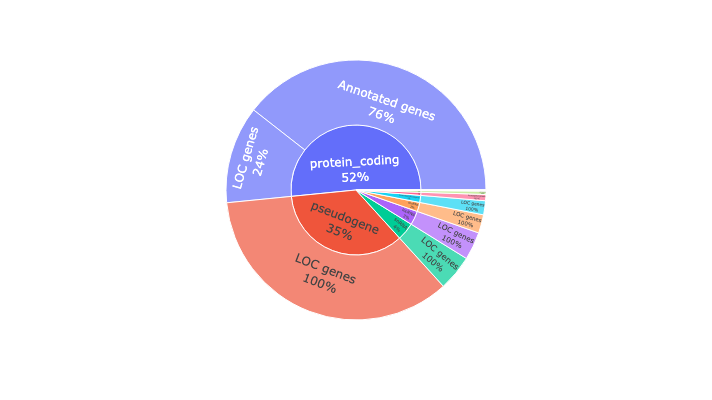

In [108]:
## Copy the dataframe
plot_octDeg1 = gff_octDeg1[["biotype", "gene_name","is_LOC_gene"]].copy()
## Drop the NaN values 
plot_octDeg1_clean = plot_octDeg1.dropna()
## Drop any duplicates for genes 
plot_octDeg1_clean = plot_octDeg1_clean.drop_duplicates()



## Plot just the biotype and is_LOC_gene field
sunburst_data = (
    plot_octDeg1_clean
    .groupby(["biotype", "is_LOC_gene"])
    .size()
    .reset_index(name="count"))
# print(sunburst_data.head())
fig = px.sunburst(
    sunburst_data,
    path=["biotype", "is_LOC_gene"],  # Hierarchy
    values="count",                                 # Aggregation metric
    # title="OctDeg1 gene type distribution",
    width=400, height=400)

# Customize the text display
fig.update_traces(
    textinfo='label+percent parent',  # Shows category, percentage, and count
    # insidetextorientation='radial'  # Better text orientation
)
# Save as PNG (high quality)
fig.write_image("sunburst_plot_octDeg1.png", scale=3)  # scale=3 for high DPI
fig.show()

In [109]:
plot_octDeg1 = gff_octDeg1[["biotype", "gene_name","is_LOC_gene","duplicated_status"]].copy()
# Drop the NaN values 
plot_octDeg1_clean = plot_octDeg1.dropna()
## Drop any duplicates for genes 
plot_octDeg1_clean = plot_octDeg1_clean.drop_duplicates()

## Only care about the protein coding genes 
plot_octDeg1_pc = plot_octDeg1_clean[plot_octDeg1_clean["biotype"] == "protein_coding"]
## Plot just the biotype and is_LOC_gene field
sunburst_data = (
    plot_octDeg1_pc
    .groupby(["biotype", "is_LOC_gene","duplicated_status"])
    .size()
    .reset_index(name="count"))
sunburst_data


,biotype,is_LOC_gene,duplicated_status,count
0,protein_coding,Annotated genes,Unique,15762
1,protein_coding,LOC genes,Unique,4848


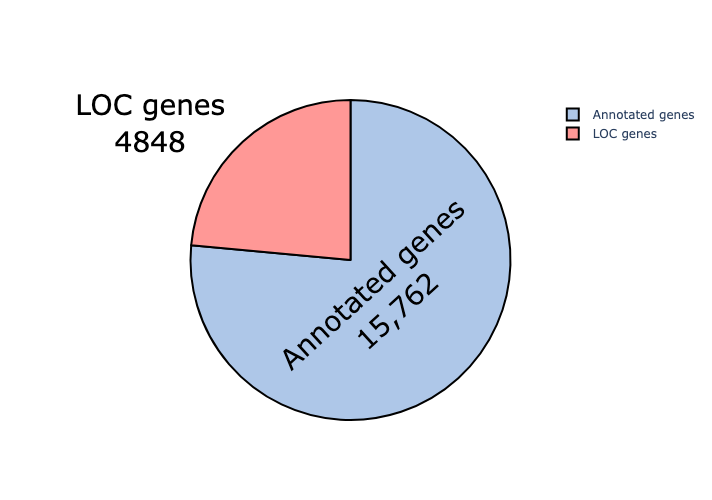

In [110]:
colors=["#aec7e8","#ff9896","#98df8a"]

fig = go.Figure(data=[go.Pie(labels=sunburst_data["is_LOC_gene"],
                             values=sunburst_data["count"])],
                   layout=go.Layout(
        width=500,
        height=500
    ))
fig.update_traces(hoverinfo='percent', textinfo='label+value', textfont=dict(color='black', size=28),
                  marker=dict(colors=colors, line=dict(color='#000000', width=2)))

# Save the figure
fig.write_image("pie_chart_octDeg1.svg", format="svg", engine="kaleido")
fig.write_image("pie_chart_octDeg1.png", scale=3)  # High resolution PNG
fig.show()

## LiftOff annotation

In [111]:
gff_lo
gff_lo['biotype'] = gff_lo['attributes'].str.extract(r'gene_biotype=([^;]+)', expand=False)
gff_lo['biotype'] = gff_lo['biotype'].ffill()

gff_lo['gene_name'] = gff_lo['attributes'].str.extract(r'ID=gene-([^;]+)', expand=False)
# gff_lo['gene_name'] = gff_lo['gene_name'].ffill()

gff_lo['is_LOC_gene'] = np.where(
    gff_lo['gene_name'].str.match(r'^LOC\d{9}$', na=False),
    'LOC genes',
    'Annotated genes'
)

not_na_mask=gff_lo['gene_name'].notna()
# Create boolean mask for duplicated gene names (including all duplicates)
duplicate_mask = not_na_mask & gff_lo['gene_name'].duplicated(keep="first")
# Initialize the column
gff_lo.loc[not_na_mask,'duplicated_status'] = 'Unique'  # Default value for all genes
# Update only the duplicated genes
gff_lo.loc[duplicate_mask, 'duplicated_status'] = 'Ortholog/Duplicate'
gff_lo.head(10)

/tscc/lustre/ddn/scratch/jhc103/temp-dir-fast/ipykernel_1104888/3034825259.py:18: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'Unique' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.



,seqid,source,type,start,end,score,strand,phase,attributes,biotype,gene_name,is_LOC_gene,duplicated_status
0,NC_020661.1,Liftoff,gene,2740,3697,.,+,.,ID=gene-ND1;Dbxref=GeneID:14864912;Name=ND1;gb...,protein_coding,ND1,Annotated genes,Unique
1,NC_020661.1,Liftoff,mRNA,2740,3697,.,+,.,ID=rna-ND1;Parent=gene-ND1;Dbxref=GeneID:14864...,protein_coding,NaN,Annotated genes,NaN
2,NC_020661.1,Liftoff,exon,2740,3697,.,+,.,ID=exon-ND1-1;Parent=rna-ND1;Dbxref=GeneID:148...,protein_coding,NaN,Annotated genes,NaN
3,NC_020661.1,Liftoff,CDS,2740,3697,.,+,.,ID=cds-YP_007625549.1;Parent=rna-ND1;Dbxref=Ge...,protein_coding,NaN,Annotated genes,NaN
4,NC_020661.1,Liftoff,gene,3905,4946,.,+,.,ID=gene-ND2;Dbxref=GeneID:14864910;Name=ND2;gb...,protein_coding,ND2,Annotated genes,Unique
5,NC_020661.1,Liftoff,mRNA,3905,4946,.,+,.,ID=rna-ND2;Parent=gene-ND2;Dbxref=GeneID:14864...,protein_coding,NaN,Annotated genes,NaN
6,NC_020661.1,Liftoff,exon,3905,4946,.,+,.,ID=exon-ND2-1;Parent=rna-ND2;Dbxref=GeneID:148...,protein_coding,NaN,Annotated genes,NaN
7,NC_020661.1,Liftoff,CDS,3905,4946,.,+,.,ID=cds-YP_007625550.1;Parent=rna-ND2;Dbxref=Ge...,protein_coding,NaN,Annotated genes,NaN
8,NC_020661.1,Liftoff,gene,5344,6888,.,+,.,ID=gene-COX1;Dbxref=GeneID:14864919;Name=COX1;...,protein_coding,COX1,Annotated genes,Unique
9,NC_020661.1,Liftoff,mRNA,5344,6888,.,+,.,ID=rna-COX1;Parent=gene-COX1;Dbxref=GeneID:148...,protein_coding,NaN,Annotated genes,NaN


In [112]:
gff_lo["duplicated_status"].value_counts()

duplicated_status
Unique    25109
Name: count, dtype: int64

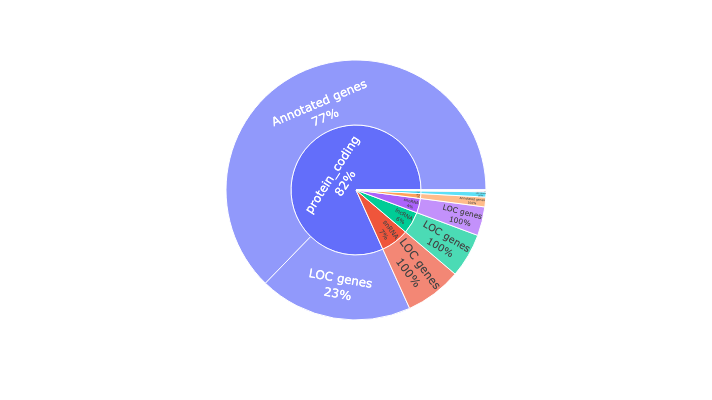

In [113]:
## Copy the dataframe
plot_lo = gff_lo[["biotype", "gene_name","is_LOC_gene"]].copy()
## Drop the NaN values 
plot_lo_clean = plot_lo.dropna()
## Drop any duplicates for genes 
plot_lo_clean = plot_lo_clean.drop_duplicates()
## Plot just the biotype and is_LOC_gene field
sunburst_data = (
    plot_lo_clean
    .groupby(["biotype", "is_LOC_gene"])
    .size()
    .reset_index(name="count"))
# print(sunburst_data.head())
fig = px.sunburst(
    sunburst_data,
    path=["biotype", "is_LOC_gene"],  # Hierarchy
    values="count",                                 # Aggregation metric
    # title="LiftOff transfered OctDeg1 gene type distribution",
    width=400, height=400)

# Customize the text display
fig.update_traces(
    textinfo='label+percent parent',  # Shows category, percentage, and count
    # insidetextorientation='radial'  # Better text orientation
)
# Save as PNG (high quality)
fig.write_image("sunburst_plot_liftOff.png", scale=3)  # scale=3 for high DPI
fig.show()

In [114]:
plot_lo = gff_lo[["biotype", "gene_name","is_LOC_gene","duplicated_status"]].copy()
## Drop the NaN values 
plot_lo_clean = plot_lo.dropna()
## Drop any duplicates for genes 
plot_lo_clean = plot_lo_clean.drop_duplicates()

## Only care about the protein coding genes 
plot_lo_pc = plot_lo_clean[plot_lo_clean["biotype"] == "protein_coding"]
## Plot just the biotype and is_LOC_gene field
sunburst_data = (
    plot_lo_pc
    .groupby(["biotype", "is_LOC_gene","duplicated_status"])
    .size()
    .reset_index(name="count"))
sunburst_data

,biotype,is_LOC_gene,duplicated_status,count
0,protein_coding,Annotated genes,Unique,15750
1,protein_coding,LOC genes,Unique,4782


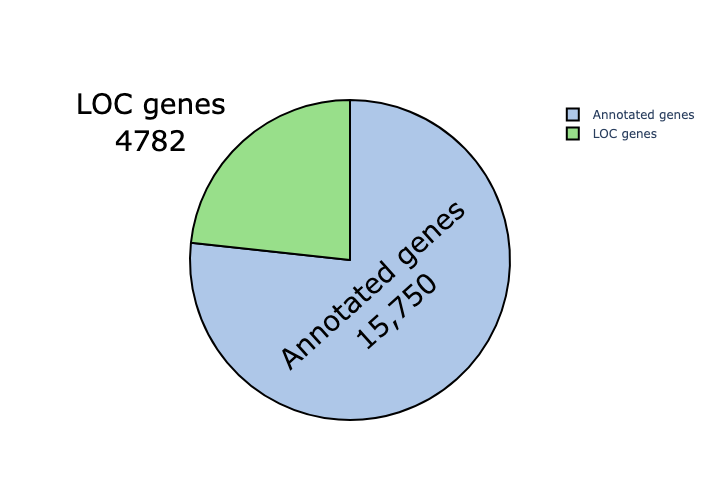

In [115]:
colors=["#aec7e8","#98df8a","#ff9896"]

fig = go.Figure(data=[go.Pie(labels=sunburst_data["is_LOC_gene"],
                             values=sunburst_data["count"])],
                   layout=go.Layout(
        width=500,
        height=500
    ))
fig.update_traces(hoverinfo='percent', textinfo='label+value', textfont=dict(color='black', size=28),
                  marker=dict(colors=colors, line=dict(color='#000000', width=2)))

# Save the figure
fig.write_image("pie_chart_liftOff.svg", format="svg", engine="kaleido")
fig.write_image("pie_chart_liftOff.png", scale=3)  # High resolution PNG
fig.show()

## Braker Uniprot annotated annotation

In [116]:
gff_dn['type'].value_counts()

type
CDS                393414
exon               393414
intron             355559
mRNA                75710
start_codon         37840
stop_codon          37830
gene                26395
three_prime_UTR     14415
Name: count, dtype: int64

In [117]:
gff_dn['geneU'] = gff_dn[gff_dn['type']=="gene"]['attributes'].str.extract(r'Name=([^;]+)', expand=False).str.upper()
# gff_dn['gene'] = gff_dn['gene1'] + '_' + gff_dn[gff_dn['type'] == "gene"]['start'].astype(str)

mask_notF=(gff_dn["type"]=="gene")&(gff_dn['geneU'].isna())
mask_f=(gff_dn["type"]=="gene")&(~gff_dn['geneU'].isna())
gff_dn.loc[mask_notF,"feature_type"] = "pseudogene"
gff_dn.loc[mask_f,"feature_type"] = "protein_coding"
gff_dn['gene'] = gff_dn['feature_type'] + '_' + gff_dn[gff_dn['type'] == "gene"]['start'].astype(str) + "_" + gff_dn[gff_dn['type'] == "gene"]['end'].astype(str)


# Initialize 'duplicated_status' column with NaN (or None)
gff_dn['duplicated_status'] = np.nan

# Define valid genes (non-NA geneU)
valid_gene_mask = gff_dn['geneU'].notna()

# Create boolean mask of duplicates
duplicate_mask = gff_dn.loc[valid_gene_mask, 'geneU'].duplicated(keep=False)

gff_dn["duplicated_status"] = "Not annotated"
# Assign labels
gff_dn.loc[valid_gene_mask, 'duplicated_status'] = np.where(
    duplicate_mask,
    "Putative Paralog",
    'Unique'
)

/tscc/lustre/ddn/scratch/jhc103/temp-dir-fast/ipykernel_1104888/1380731508.py:6: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'pseudogene' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.



In [118]:
gff_dn

,seqid,source,type,start,end,score,strand,phase,attributes,geneU,feature_type,gene,duplicated_status
0,chr1,GeneMark.hmm3,stop_codon,81881,81883,.,-,0,.,NaN,NaN,NaN,Not annotated
1,chr1,GeneMark.hmm3,gene,81881,82024,.,-,.,ID=g1;Name=HAUS4,HAUS4,protein_coding,protein_coding_81881_82024,Putative Paralog
2,chr1,GeneMark.hmm3,mRNA,81881,82024,.,-,.,ID=g1.t1;Parent=g1,NaN,NaN,NaN,Not annotated
3,chr1,GeneMark.hmm3,CDS,81881,82024,.,-,0,.,NaN,NaN,NaN,Not annotated
4,chr1,GeneMark.hmm3,exon,81881,82024,.,-,0,.,NaN,NaN,NaN,Not annotated
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1334572,seq37,AUGUSTUS,mRNA,237491,238841,0.72,-,.,.,NaN,NaN,NaN,Not annotated
1334573,seq37,AUGUSTUS,intron,237734,238304,0.91,-,.,.,NaN,NaN,NaN,Not annotated
1334574,seq37,AUGUSTUS,CDS,238305,238841,0.91,-,0,.,NaN,NaN,NaN,Not annotated
1334575,seq37,AUGUSTUS,exon,238305,238841,.,-,.,.,NaN,NaN,NaN,Not annotated


In [119]:
gff_dn

,seqid,source,type,start,end,score,strand,phase,attributes,geneU,feature_type,gene,duplicated_status
0,chr1,GeneMark.hmm3,stop_codon,81881,81883,.,-,0,.,NaN,NaN,NaN,Not annotated
1,chr1,GeneMark.hmm3,gene,81881,82024,.,-,.,ID=g1;Name=HAUS4,HAUS4,protein_coding,protein_coding_81881_82024,Putative Paralog
2,chr1,GeneMark.hmm3,mRNA,81881,82024,.,-,.,ID=g1.t1;Parent=g1,NaN,NaN,NaN,Not annotated
3,chr1,GeneMark.hmm3,CDS,81881,82024,.,-,0,.,NaN,NaN,NaN,Not annotated
4,chr1,GeneMark.hmm3,exon,81881,82024,.,-,0,.,NaN,NaN,NaN,Not annotated
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1334572,seq37,AUGUSTUS,mRNA,237491,238841,0.72,-,.,.,NaN,NaN,NaN,Not annotated
1334573,seq37,AUGUSTUS,intron,237734,238304,0.91,-,.,.,NaN,NaN,NaN,Not annotated
1334574,seq37,AUGUSTUS,CDS,238305,238841,0.91,-,0,.,NaN,NaN,NaN,Not annotated
1334575,seq37,AUGUSTUS,exon,238305,238841,.,-,.,.,NaN,NaN,NaN,Not annotated


In [120]:
gff_dn["feature_type"].value_counts()

feature_type
protein_coding    23547
pseudogene         2848
Name: count, dtype: int64

In [121]:
gff_dn[(gff_dn["type"]=="gene")&(gff_dn['feature_type']=="pseudogene")]

,seqid,source,type,start,end,score,strand,phase,attributes,geneU,feature_type,gene,duplicated_status
401,chr1,GeneMark.hmm3,gene,502725,507080,.,+,.,ID=g16,NaN,pseudogene,pseudogene_502725_507080,Not annotated
444,chr1,gmst,gene,554756,717488,.,+,.,ID=g19,NaN,pseudogene,pseudogene_554756_717488,Not annotated
481,chr1,AUGUSTUS,gene,591621,594486,.,+,.,ID=g20,NaN,pseudogene,pseudogene_591621_594486,Not annotated
1029,chr1,AUGUSTUS,gene,837715,841454,.,+,.,ID=g29,NaN,pseudogene,pseudogene_837715_841454,Not annotated
1174,chr1,gmst,gene,866373,866765,.,-,.,ID=g33,NaN,pseudogene,pseudogene_866373_866765,Not annotated
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1332492,chrY,AUGUSTUS,gene,63496550,63496858,.,-,.,ID=g26357,NaN,pseudogene,pseudogene_63496550_63496858,Not annotated
1332499,chrY,AUGUSTUS,gene,63497859,63498416,.,-,.,ID=g26358,NaN,pseudogene,pseudogene_63497859_63498416,Not annotated
1334420,chrY,AUGUSTUS,gene,84997566,84999475,.,+,.,ID=g26383,NaN,pseudogene,pseudogene_84997566_84999475,Not annotated
1334444,chrY,GeneMark.hmm3,gene,85524372,85528200,.,+,.,ID=g26386,NaN,pseudogene,pseudogene_85524372_85528200,Not annotated


In [122]:
gff_dn[(gff_dn["type"]=="gene")&(~gff_dn['geneU'].isna())]

,seqid,source,type,start,end,score,strand,phase,attributes,geneU,feature_type,gene,duplicated_status
1,chr1,GeneMark.hmm3,gene,81881,82024,.,-,.,ID=g1;Name=HAUS4,HAUS4,protein_coding,protein_coding_81881_82024,Putative Paralog
8,chr1,GeneMark.hmm3,gene,82103,82837,.,-,.,ID=g2;Name=HAUS4,HAUS4,protein_coding,protein_coding_82103_82837,Putative Paralog
14,chr1,AUGUSTUS,gene,164383,196302,.,-,.,ID=g3;Name=GABBR1,GABBR1,protein_coding,protein_coding_164383_196302,Unique
161,chr1,AUGUSTUS,gene,228534,242344,.,+,.,ID=g4;Name=MOG,MOG,protein_coding,protein_coding_228534_242344,Unique
183,chr1,AUGUSTUS,gene,241809,248331,.,-,.,ID=g5;Name=ZFP57,ZFP57,protein_coding,protein_coding_241809_248331,Putative Paralog
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1334538,seq31,AUGUSTUS,gene,353629,356453,.,-,.,ID=g26391;Name=NKAPD1,NKAPD1,protein_coding,protein_coding_353629_356453,Putative Paralog
1334547,seq31,AUGUSTUS,gene,367766,368644,.,-,.,ID=g26392;Name=NKAPD1,NKAPD1,protein_coding,protein_coding_367766_368644,Putative Paralog
1334554,seq31,AUGUSTUS,gene,697591,698610,.,-,.,ID=g26393;Name=Rad51,RAD51,protein_coding,protein_coding_697591_698610,Putative Paralog
1334561,seq31,AUGUSTUS,gene,701545,702564,.,-,.,ID=g26394;Name=Rad51,RAD51,protein_coding,protein_coding_701545_702564,Putative Paralog


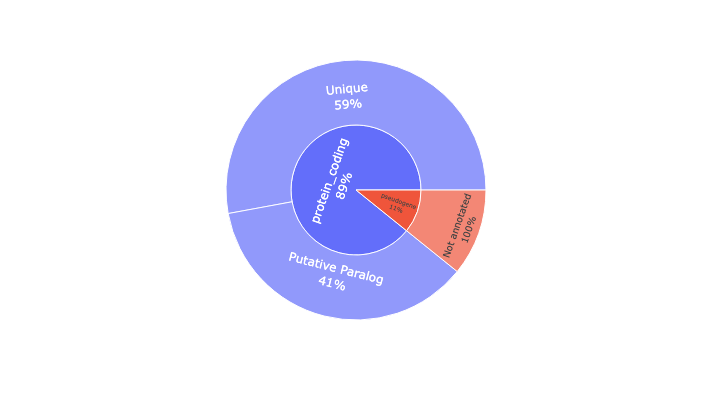

In [123]:
## Copy the dataframe
plot_dn = gff_dn[gff_dn["type"]=="gene"][["feature_type", "gene","duplicated_status"]].copy()
## Drop the NaN values 
plot_dn_clean = plot_dn.dropna()
## Drop any duplicates for genes 
plot_dn_clean = plot_dn_clean.drop_duplicates()
## Plot just the biotype and is_LOC_gene field
sunburst_data = (
    plot_dn_clean
    .groupby(["feature_type", "duplicated_status"])
    .size()
    .reset_index(name="count"))
# print(sunburst_data.head())
fig = px.sunburst(
    sunburst_data,
    path=["feature_type", "duplicated_status"],  # Hierarchy
    values="count",                                 # Aggregation metric
    # title="Braker gene type distribution",
    width=400, height=400)

# Customize the text display
fig.update_traces(
    textinfo='label+percent parent',  # Shows category, percentage, and count
    # insidetextorientation='radial'  # Better text orientation
)
# Save as PNG (high quality)
fig.write_image("sunburst_plot_braker.png", scale=3)  # scale=3 for high DPI
fig.show()

In [124]:
gff_dn.head()

,seqid,source,type,start,end,score,strand,phase,attributes,geneU,feature_type,gene,duplicated_status
0,chr1,GeneMark.hmm3,stop_codon,81881,81883,.,-,0,.,NaN,NaN,NaN,Not annotated
1,chr1,GeneMark.hmm3,gene,81881,82024,.,-,.,ID=g1;Name=HAUS4,HAUS4,protein_coding,protein_coding_81881_82024,Putative Paralog
2,chr1,GeneMark.hmm3,mRNA,81881,82024,.,-,.,ID=g1.t1;Parent=g1,NaN,NaN,NaN,Not annotated
3,chr1,GeneMark.hmm3,CDS,81881,82024,.,-,0,.,NaN,NaN,NaN,Not annotated
4,chr1,GeneMark.hmm3,exon,81881,82024,.,-,0,.,NaN,NaN,NaN,Not annotated


In [125]:
plot_dn = gff_dn[["feature_type", "gene","duplicated_status"]].copy()
## Drop the NaN values 
plot_dn_clean = plot_dn.dropna()
## Drop any duplicates for genes 
plot_dn_clean = plot_dn_clean.drop_duplicates()

## Only care about the protein coding genes 
plot_dn_pc = plot_dn_clean[plot_dn_clean["feature_type"] == "protein_coding"]
## Plot just the biotype and is_LOC_gene field
sunburst_data = (
    plot_dn_pc
    .groupby(["feature_type", "duplicated_status"])
    .size()
    .reset_index(name="count"))
sunburst_data

,feature_type,duplicated_status,count
0,protein_coding,Putative Paralog,9582
1,protein_coding,Unique,13961


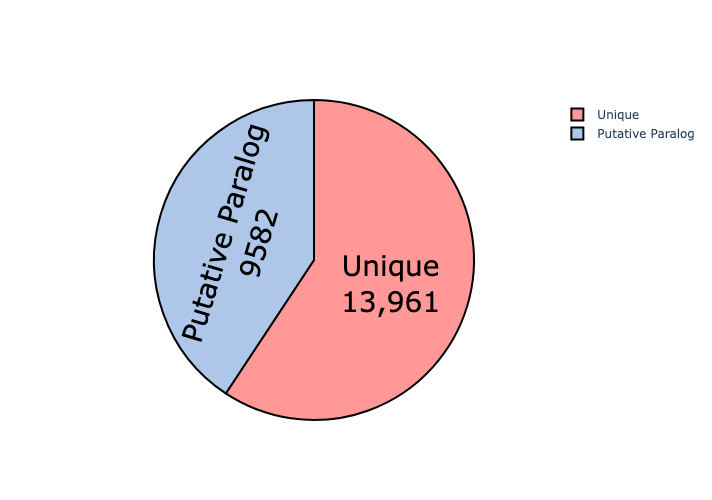

In [126]:
colors=["#aec7e8","#ff9896","#98df8a"]

fig = go.Figure(data=[go.Pie(labels=sunburst_data["duplicated_status"],
                             values=sunburst_data["count"])],    layout=go.Layout(
        width=500,
        height=500
    ))
fig.update_traces(hoverinfo='percent', textinfo='label+value', textfont=dict(color='black', size=28),
                  marker=dict(colors=colors, line=dict(color='#000000', width=2)))

# Save the figure
fig.write_image("pie_chart_braker.svg", format="svg", engine="kaleido")
fig.write_image("pie_chart_braker.png", scale=3)  # High resolution PNG
fig.show()

## Final annotation

In [127]:
gff_final['gene_name'] = gff_final['attributes'].str.extract(r'ID=gene-([^;]+)', expand=False)


In [128]:
gff_final

,seqid,source,type,start,end,score,strand,phase,attributes,gene_name
0,chrX,Liftoff,gene,25545,30066,.,-,.,ID=gene-LOC111814891;Dbxref=GeneID:111814891;N...,LOC111814891
1,chrX,Liftoff,mRNA,25545,30066,.,-,.,ID=rna-XM_023708780.1;Parent=gene-LOC111814891...,NaN
2,chrX,Liftoff,exon,25545,27462,.,-,.,ID=exon-XM_023708780.1-4;Parent=rna-XM_0237087...,NaN
3,chrX,Liftoff,exon,29974,30066,.,-,.,ID=exon-XM_023708780.1-3;Parent=rna-XM_0237087...,NaN
4,chrX,Liftoff,CDS,27394,27462,.,-,.,ID=cds-XP_023564548.1;Parent=rna-XM_023708780....,NaN
...,...,...,...,...,...,...,...,...,...,...
1205370,seq200,Liftoff,tRNA,2727,2798,.,+,.,ID=rna-Trnag-ucc-7;Parent=gene-Trnag-ucc-7;Dbx...,NaN
1205371,seq200,Liftoff,exon,2727,2798,.,+,.,ID=exon-Trnag-ucc-7-1;Parent=rna-Trnag-ucc-7;D...,NaN
1205372,seq200,Liftoff,gene,16264,16334,.,-,.,ID=gene-Trnag-gcc-6;Dbxref=GeneID:111815632;Na...,Trnag-gcc-6
1205373,seq200,Liftoff,tRNA,16264,16334,.,-,.,ID=rna-Trnag-gcc-6;Parent=gene-Trnag-gcc-6;Dbx...,NaN


In [129]:
list_nc=pd.read_csv(f"{PROJ_ROOT}/code/jupyter-notebook-script/gff-build/final-list/gene_LOC_nameChange_unique.tsv", sep="\t", index_col=0)
list_ga=pd.read_csv(f"{PROJ_ROOT}/code/jupyter-notebook-script/gff-build/final-list/gene_gBraker_toAdd_unique.tsv", sep="\t", index_col=0)
list_gr=pd.read_csv(f"{PROJ_ROOT}/code/jupyter-notebook-script/gff-build/final-list/gene_LOC_replace_unique.tsv", sep="\t", index_col=0)

print(list_nc.shape)
print(list_ga.shape)
print(list_gr.shape)

(2289, 2)
(2506, 2)
(319, 2)


In [130]:
list_nc.head()

,loc_gene,new_gene_name
0,gene-LOC101563936,GRB2-l1
1,gene-LOC101591824,TRIM39
2,gene-LOC111818433,PRRC2A
3,gene-LOC101571660,HSPA1B
4,gene-LOC101566596,C4B


In [131]:
list_ga.head()

,gene_id,new_gene_name
0,g25030,H2AB2
1,g25166,MAGEA10-dl1
2,g25188,EEF2-dl1
3,g25200,PLRG1-dl1
4,g25206,TRAPPC1-dl1


In [132]:
list_gr

,loc_gene,new_gene_name
0,gene-LOC111818628,ASCC1
1,gene-Ascc1,ASCC1
2,gene-Rpp30,RPP30
3,gene-LOC101578397,RPP30
4,gene-LOC111818377,NGEF
...,...,...
314,gene-Elk1,ELK1
315,gene-LOC111812234,ALG13-rl1
316,gene-LOC101584458,ALG13-rl1
317,gene-LOC101572273,MAGED4-rl1


In [133]:
gff_final.head()

,seqid,source,type,start,end,score,strand,phase,attributes,gene_name
0,chrX,Liftoff,gene,25545,30066,.,-,.,ID=gene-LOC111814891;Dbxref=GeneID:111814891;N...,LOC111814891
1,chrX,Liftoff,mRNA,25545,30066,.,-,.,ID=rna-XM_023708780.1;Parent=gene-LOC111814891...,NaN
2,chrX,Liftoff,exon,25545,27462,.,-,.,ID=exon-XM_023708780.1-4;Parent=rna-XM_0237087...,NaN
3,chrX,Liftoff,exon,29974,30066,.,-,.,ID=exon-XM_023708780.1-3;Parent=rna-XM_0237087...,NaN
4,chrX,Liftoff,CDS,27394,27462,.,-,.,ID=cds-XP_023564548.1;Parent=rna-XM_023708780....,NaN


In [134]:
test = gff_final.copy()
# Extract biotype from attributes (for gene features)
mask = (test["type"] == "gene")  # Assuming column is "type" not "test"
test.loc[mask, 'biotype'] = (
    test.loc[mask, 'attributes']
    .str.extract(r'gene_biotype=([^;]+)', expand=False)
    .fillna('protein_coding')  # Default to protein_coding if no match
)
# For non-gene features, you might want to set to NaN or another value
test.loc[~mask, 'biotype'] = np.nan  # or 'non_gene_feature'

## Create gene names
test.loc[mask,'gene_name'] = test.loc[mask,'attributes'].str.extract(r'ID=gene-([^;]+)', expand=False).str.upper()
# Create cleaned gene names by removing -lX and -dlX suffixes
test['gene_name_undup'] = test['gene_name'].str.replace(
    r'-(D?R?L\d+)$',  # Matches -lX or -dlX or -rlX at end of string
    '', 
    regex=True
)

test.loc[mask,'is_LOC_gene'] = np.where(
    test.loc[mask,'gene_name'].str.match(r'^LOC\d{9}$', na=False),
    'LOC genes',
    'Annotated genes'
)

test.loc[mask,'origin'] = test.loc[mask,'attributes'].str.extract(r'origin=([^;]+)', expand=False).fillna('liftoff')


In [135]:
test

,seqid,source,type,start,end,score,strand,phase,attributes,gene_name,biotype,gene_name_undup,is_LOC_gene,origin
0,chrX,Liftoff,gene,25545,30066,.,-,.,ID=gene-LOC111814891;Dbxref=GeneID:111814891;N...,LOC111814891,protein_coding,LOC111814891,LOC genes,liftoff
1,chrX,Liftoff,mRNA,25545,30066,.,-,.,ID=rna-XM_023708780.1;Parent=gene-LOC111814891...,NaN,NaN,NaN,NaN,NaN
2,chrX,Liftoff,exon,25545,27462,.,-,.,ID=exon-XM_023708780.1-4;Parent=rna-XM_0237087...,NaN,NaN,NaN,NaN,NaN
3,chrX,Liftoff,exon,29974,30066,.,-,.,ID=exon-XM_023708780.1-3;Parent=rna-XM_0237087...,NaN,NaN,NaN,NaN,NaN
4,chrX,Liftoff,CDS,27394,27462,.,-,.,ID=cds-XP_023564548.1;Parent=rna-XM_023708780....,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1205370,seq200,Liftoff,tRNA,2727,2798,.,+,.,ID=rna-Trnag-ucc-7;Parent=gene-Trnag-ucc-7;Dbx...,NaN,NaN,NaN,NaN,NaN
1205371,seq200,Liftoff,exon,2727,2798,.,+,.,ID=exon-Trnag-ucc-7-1;Parent=rna-Trnag-ucc-7;D...,NaN,NaN,NaN,NaN,NaN
1205372,seq200,Liftoff,gene,16264,16334,.,-,.,ID=gene-Trnag-gcc-6;Dbxref=GeneID:111815632;Na...,TRNAG-GCC-6,tRNA,TRNAG-GCC-6,Annotated genes,liftoff
1205373,seq200,Liftoff,tRNA,16264,16334,.,-,.,ID=rna-Trnag-gcc-6;Parent=gene-Trnag-gcc-6;Dbx...,NaN,NaN,NaN,NaN,NaN


In [136]:
test.head()

,seqid,source,type,start,end,score,strand,phase,attributes,gene_name,biotype,gene_name_undup,is_LOC_gene,origin
0,chrX,Liftoff,gene,25545,30066,.,-,.,ID=gene-LOC111814891;Dbxref=GeneID:111814891;N...,LOC111814891,protein_coding,LOC111814891,LOC genes,liftoff
1,chrX,Liftoff,mRNA,25545,30066,.,-,.,ID=rna-XM_023708780.1;Parent=gene-LOC111814891...,NaN,NaN,NaN,NaN,NaN
2,chrX,Liftoff,exon,25545,27462,.,-,.,ID=exon-XM_023708780.1-4;Parent=rna-XM_0237087...,NaN,NaN,NaN,NaN,NaN
3,chrX,Liftoff,exon,29974,30066,.,-,.,ID=exon-XM_023708780.1-3;Parent=rna-XM_0237087...,NaN,NaN,NaN,NaN,NaN
4,chrX,Liftoff,CDS,27394,27462,.,-,.,ID=cds-XP_023564548.1;Parent=rna-XM_023708780....,NaN,NaN,NaN,NaN,NaN


In [137]:
## Add column indicating whether it is from rename or addition 
test["added_features"] = test["gene_name"].isin(list_ga["new_gene_name"].str.upper())
test["renamed_features"] = test["gene_name"].isin(list_nc["new_gene_name"].str.upper())
test["replaced_features"] = test["gene_name"].isin(list_gr["new_gene_name"].str.upper())

## Build paralog-copy column: predicted paralog copies = gene name ends in -(D?R?L\d+)$ (e.g. -L1, -DL1, -RL1)
not_na_mask = test['gene_name'].notna()
suffix_mask = test['gene_name'].str.contains(r'-(D?R?L\d+)$', na=False, regex=True)
# Initialize the column
test.loc[not_na_mask, 'duplicated_status'] = 'Unique'  # Default value for all genes
# Mark only the suffix-bearing predicted paralog copies
test.loc[suffix_mask & not_na_mask, 'duplicated_status'] = 'Potential Paralog'

# ## Add column indicating whether the gene IS new or not 
test.loc[test["gene_name_undup"].notna(), "new_gene"] = False
test.loc[test["gene_name_undup"].notna(), "new_gene"] = ~test.loc[test["gene_name_undup"].notna(), "gene_name_undup"].isin(gff_lo["gene_name"].str.upper()) ## If it is matching then set as False to new_gene 

/tscc/lustre/ddn/scratch/jhc103/temp-dir-fast/ipykernel_1104888/3239831965.py:8: UserWarning:

This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.

/tscc/lustre/ddn/scratch/jhc103/temp-dir-fast/ipykernel_1104888/3239831965.py:10: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'Unique' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.

/tscc/lustre/ddn/scratch/jhc103/temp-dir-fast/ipykernel_1104888/3239831965.py:15: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'False' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.



In [138]:
print("Make sure the number of genes and pseudogenes matches the number of biotypes then we can safely ffill so we are not ffilling for features that don't have biotype therefore artificially intorducing mismatches")
print(sum(~test['biotype'].isna()))
print(sum((test["type"]=="gene")))
print(sum(~test['gene_name'].isna()))


Make sure the number of genes and pseudogenes matches the number of biotypes then we can safely ffill so we are not ffilling for features that don't have biotype therefore artificially intorducing mismatches
26273
26273
26273


In [139]:
test[test["gene_name_undup"]=="COX15"]

,seqid,source,type,start,end,score,strand,phase,attributes,gene_name,biotype,gene_name_undup,is_LOC_gene,origin,added_features,renamed_features,replaced_features,duplicated_status,new_gene
313913,chr4,AUGUSTUS,gene,106616263,106619077,.,-,.,ID=gene-Cox15-dl1;Name=Cox15-dl1;origin=de_novo,COX15-DL1,protein_coding,COX15,Annotated genes,de_novo,True,False,False,Potential Paralog,True
1188477,chr28,Liftoff,gene,7171846,7196884,.,-,.,ID=gene-Cox15;Dbxref=GeneID:101586038;Name=Cox...,COX15,protein_coding,COX15,Annotated genes,rename,False,True,False,Unique,True


In [140]:
test.head()

,seqid,source,type,start,end,score,strand,phase,attributes,gene_name,biotype,gene_name_undup,is_LOC_gene,origin,added_features,renamed_features,replaced_features,duplicated_status,new_gene
0,chrX,Liftoff,gene,25545,30066,.,-,.,ID=gene-LOC111814891;Dbxref=GeneID:111814891;N...,LOC111814891,protein_coding,LOC111814891,LOC genes,liftoff,False,False,False,Unique,False
1,chrX,Liftoff,mRNA,25545,30066,.,-,.,ID=rna-XM_023708780.1;Parent=gene-LOC111814891...,NaN,NaN,NaN,NaN,NaN,False,False,False,NaN,NaN
2,chrX,Liftoff,exon,25545,27462,.,-,.,ID=exon-XM_023708780.1-4;Parent=rna-XM_0237087...,NaN,NaN,NaN,NaN,NaN,False,False,False,NaN,NaN
3,chrX,Liftoff,exon,29974,30066,.,-,.,ID=exon-XM_023708780.1-3;Parent=rna-XM_0237087...,NaN,NaN,NaN,NaN,NaN,False,False,False,NaN,NaN
4,chrX,Liftoff,CDS,27394,27462,.,-,.,ID=cds-XP_023564548.1;Parent=rna-XM_023708780....,NaN,NaN,NaN,NaN,NaN,False,False,False,NaN,NaN


In [141]:
test[test["gene_name"]=="MAGEA10-DL1"]

,seqid,source,type,start,end,score,strand,phase,attributes,gene_name,biotype,gene_name_undup,is_LOC_gene,origin,added_features,renamed_features,replaced_features,duplicated_status,new_gene
4994,chrX,AUGUSTUS,gene,8050412,8052067,.,+,.,ID=gene-Magea10-dl1;Name=Magea10-dl1;origin=de...,MAGEA10-DL1,protein_coding,MAGEA10,Annotated genes,de_novo,True,False,False,Potential Paralog,True


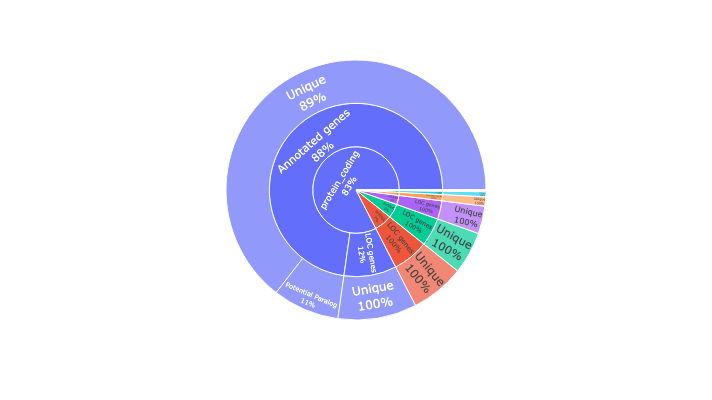

In [142]:

## Copy the dataframe
plot_final = test[["biotype", "gene_name","is_LOC_gene","duplicated_status","renamed_features","added_features","new_gene"]].copy()
## Drop the NaN values 
plot_final_clean = plot_final.dropna()
## Drop any duplicates for genes 
plot_final_clean = plot_final_clean.drop_duplicates()
## Plot just the biotype and is_LOC_gene field
sunburst_data = (
    plot_final_clean
    .groupby(["biotype", "is_LOC_gene","duplicated_status"])
    .size()
    .reset_index(name="count"))
# print(sunburst_data.head())
fig = px.sunburst(
    sunburst_data,
    path=["biotype", "is_LOC_gene","duplicated_status"],  # Hierarchy
    values="count",                                 # Aggregation metric
    # title="Final octDeg2 gene type distribution",
    width=400, height=400)

# Customize the text display
fig.update_traces(
    textinfo='label+percent parent',  # Shows category, percentage, and count
    # insidetextorientation='radial'  # Better text orientation
)
# Save as PNG (high quality)
fig.write_image("sunburst_plot_final.png", scale=3)  # scale=3 for high DPI
fig.show()

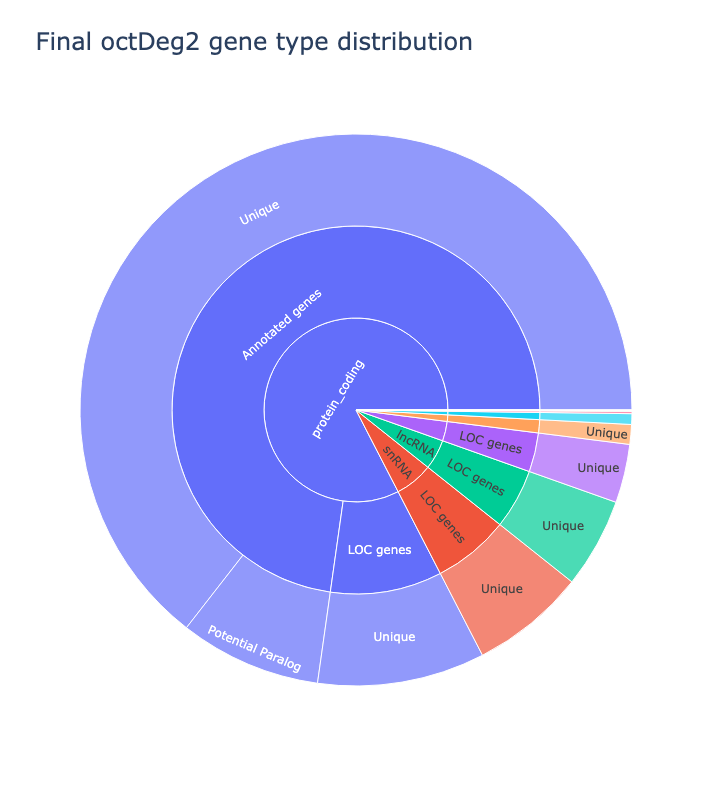

In [143]:
fig = px.sunburst(
    sunburst_data,
    path=["biotype", "is_LOC_gene","duplicated_status"],
    values="count",
    title="Final octDeg2 gene type distribution",
    width=800, 
    height=800
)

fig.update_layout(
    uniformtext=dict(minsize=10, mode='hide'),  # Increase minimum size and hide if doesn't fit
    title_font_size=24  # Increase title font size
)

# fig.update_traces(
#     textfont=dict(size=8)  # Increase text font size for all labels
# )

fig.show()

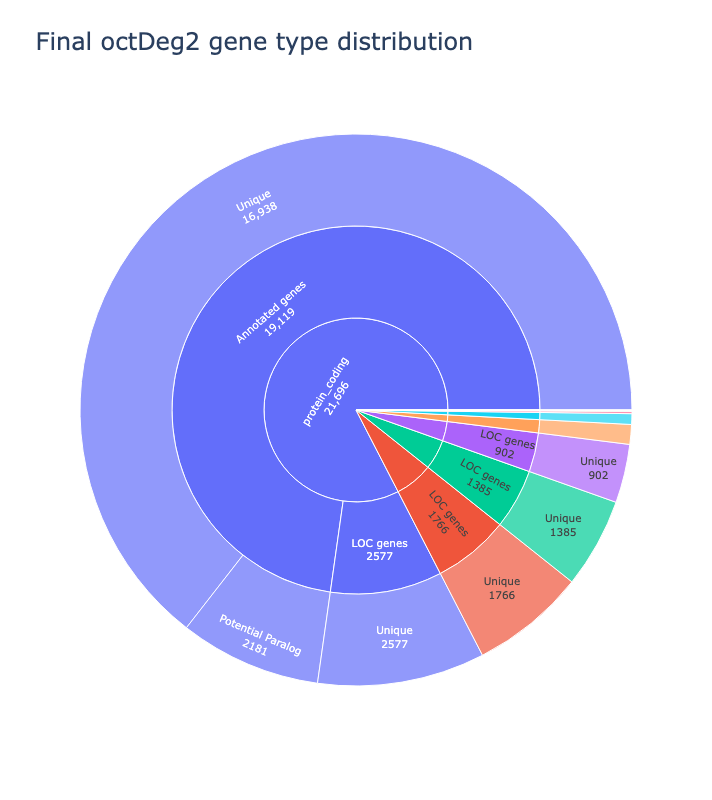

In [144]:
fig = px.sunburst(
    sunburst_data,
    path=["biotype", "is_LOC_gene", "duplicated_status"],
    values="count",
    title="Final octDeg2 gene type distribution",
    width=800,
    height=800
)

fig.update_layout(
    uniformtext=dict(minsize=10, mode='hide'),
    title_font_size=24,
    showlegend=True,  # Enable the legend in the layout
    legend=dict(
        title="Categories",  # Optional: set a title for the legend
        title_font_size=12,
        font=dict(size=10),
        x=1.05,  # Position the legend outside the chart to the right
        xanchor='left',
        y=0.5,
        yanchor='middle'
    )
)

fig.update_traces(
    textinfo='label+value',   # Show both label and value in the chart
    hovertemplate='<b>%{label}</b><br>Count: %{value}<br>Percentage: %{percentParent:.2%}<extra></extra>'
)

fig.show()

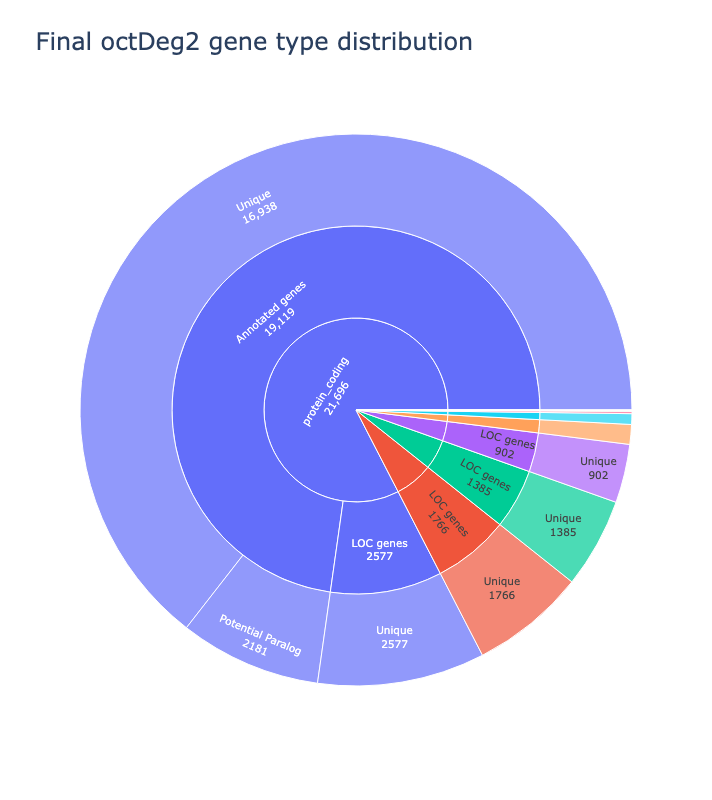

In [145]:
fig = px.sunburst(
    sunburst_data,
    path=["biotype", "is_LOC_gene","duplicated_status"],
    values="count",
    title="Final octDeg2 gene type distribution",
    width=800, 
    height=800
)

fig.update_layout(
    uniformtext=dict(minsize=10, mode='hide'),
    title_font_size=24,
    legend=dict(
        title="Categories",    # Custom legend title
        title_font_size=16,
        font=dict(size=12, family="Arial"),
        bgcolor="lightgray",   # Background color
        bordercolor="black",   # Border color
        borderwidth=1,         # Border width
        x=1.02,               # Adjust position
        xanchor='left',
        y=0.5,
        yanchor='middle',
        orientation="v"       # Vertical orientation
    )
)

fig.update_traces(
    textinfo='label+value',   # Show both label and value in the chart
    hovertemplate='<b>%{label}</b><br>Count: %{value}<br>Percentage: %{percentParent:.2%}<extra></extra>'
)

fig.show()


In [146]:
plot_final = test[["biotype", "gene_name","is_LOC_gene","duplicated_status","renamed_features","added_features","replaced_features","new_gene","origin"]].copy()
plot_final_clean = plot_final.dropna()
plot_final_clean = plot_final_clean.drop_duplicates()
plot_final_clean = plot_final_clean[plot_final_clean["biotype"] == "protein_coding"]
plot_final_clean
# ## Plot just the biotype and is_LOC_gene field
sunburst_data = (
    plot_final_clean
    .groupby(["biotype", "is_LOC_gene","duplicated_status","renamed_features","added_features","replaced_features","new_gene","origin"])
    .size()
    .reset_index(name="count"))
# sunburst_data["label"]=["Annotated duplicate", ""]
print(sunburst_data.shape)
sunburst_data

(26, 9)


,biotype,is_LOC_gene,duplicated_status,renamed_features,added_features,replaced_features,new_gene,origin,count
0,protein_coding,Annotated genes,Potential Paralog,False,False,False,False,liftoff,20
1,protein_coding,Annotated genes,Potential Paralog,False,False,False,False,rename,1
2,protein_coding,Annotated genes,Potential Paralog,False,False,False,False,replace,3
3,protein_coding,Annotated genes,Potential Paralog,False,False,False,True,rename,18
4,protein_coding,Annotated genes,Potential Paralog,False,False,False,True,replace,2
5,protein_coding,Annotated genes,Potential Paralog,False,False,True,False,replace,1
6,protein_coding,Annotated genes,Potential Paralog,False,False,True,True,replace,1
7,protein_coding,Annotated genes,Potential Paralog,False,True,False,False,de_novo,892
8,protein_coding,Annotated genes,Potential Paralog,False,True,False,True,de_novo,274
9,protein_coding,Annotated genes,Potential Paralog,True,False,False,False,liftoff,42


Found out that the newest annotation is not actually have the minor fix implemented ==> Pcdh11x in the old annotation but not in the new fixed annotation 

In [147]:
# test[(test["renamed_features"]==False)&(test["added_features"]==False)&(test["replaced_features"]==False)&(test["new_gene"]==True)&(test["type"]=="gene")]



In [148]:
sunburst_data = sunburst_data.copy()

def _label(r):
    if r['is_LOC_gene'] == 'LOC genes':
        return 'LOC genes'
    origin = r['origin']
    if origin == 'liftoff':
        if r['duplicated_status'] != 'Unique':
            return 'liftoff | characterized | paralog'
        return 'Characterized genes'
    o = {'replace': 'replaced', 'de_novo': 'added'}.get(origin, 'renamed')
    known = 'novel' if origin in ('de_novo', 'replace') else 'characterized'
    if r['duplicated_status'] != 'Unique':
        return f'{o} | {known} | paralog'
    return f'{o} | {known}'

sunburst_data['label'] = sunburst_data.apply(_label, axis=1)
sunburst_data = sunburst_data.groupby('label', as_index=False)['count'].sum()

# counter-clockwise order: characterized -> novel (non-paralog) -> paralog -> LOC
custom_order = [
    "Characterized genes",
    "renamed | characterized",
    "replaced | novel",
    "added | novel",
    "liftoff | characterized | paralog",
    "renamed | characterized | paralog",
    "replaced | novel | paralog",
    "added | novel | paralog",
    "LOC genes",
]
sunburst_data['label'] = pd.Categorical(sunburst_data['label'], categories=custom_order, ordered=True)
sunburst_data = sunburst_data.sort_values('label')
sunburst_data


,label,count
0,Characterized genes,15607
5,renamed | characterized,1036
7,replaced | novel,151
2,added | novel,144
4,liftoff | characterized | paralog,62
6,renamed | characterized | paralog,946
8,replaced | novel | paralog,7
3,added | novel | paralog,1166
1,LOC genes,2577


In [149]:
sunburst_data['label']

0                  Characterized genes
5              renamed | characterized
7                     replaced | novel
2                        added | novel
4    liftoff | characterized | paralog
6    renamed | characterized | paralog
8           replaced | novel | paralog
3              added | novel | paralog
1                            LOC genes
Name: label, dtype: category
Categories (9, object): ['Characterized genes' < 'renamed | characterized' < 'replaced | novel' < 'added | novel' ... 'renamed | characterized | paralog' < 'replaced | novel | paralog' < 'added | novel | paralog' < 'LOC genes']

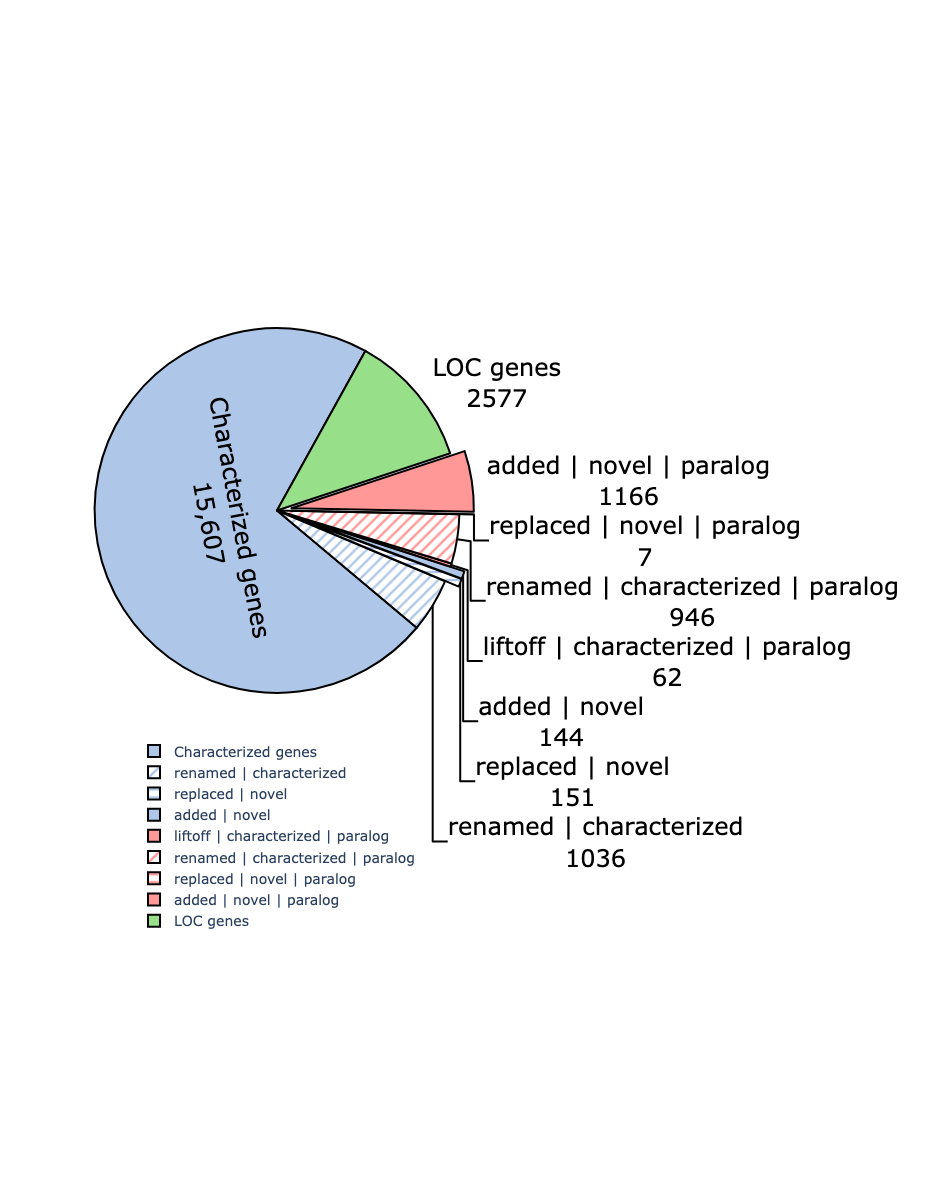

In [155]:
labels = sunburst_data['label'].astype(str).tolist()
counts = sunburst_data['count'].tolist()
# color: non-paralog = blue, paralog = red, LOC = green
colors = ['#98df8a' if l == 'LOC genes' else ('#ff9896' if 'paralog' in l else '#aec7e8') for l in labels]
pull = [0.08 if 'novel' in l else 0 for l in labels]
# origin hatch patterns: replaced = horizontal, de novo = dot, renamed = slanted
def _pattern(l):
    if l in ('LOC genes', 'Characterized genes'):
        return ''
    if l.startswith('replaced'):
        return '-'
    if l.startswith('de novo'):
        return '.'
    if l.startswith('renamed'):
        return '/'
    return ''
pattern_shape = [_pattern(l) for l in labels]


fig = go.Figure(data=[go.Pie(labels=labels, values=counts, pull=pull,
                             rotation=130, sort=False,
                             marker=dict(colors=colors, line=dict(color='#000000', width=2),
                                         pattern_shape=pattern_shape))],
                layout=go.Layout(width=1200, height=1200))
fig.update_traces(hoverinfo='label+percent', textinfo='label+value', textfont=dict(color='black', size=24))
fig.update_layout(
    legend=dict(orientation='h', yanchor='bottom', y=-0.12, xanchor='center', x=0.5,
                font=dict(size=14))
)
fig.write_image( "pie_chart_final.svg", format="svg", engine="kaleido")
fig.show()


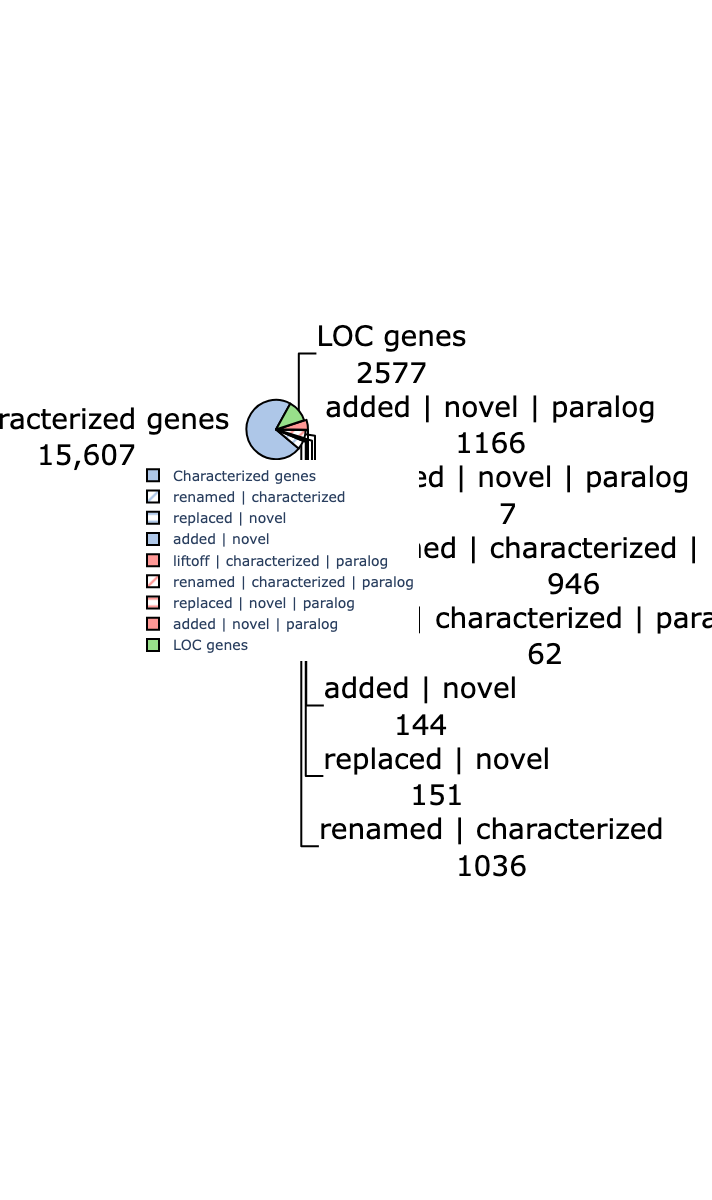

In [151]:
labels = sunburst_data['label'].astype(str).tolist()
counts = sunburst_data['count'].tolist()
# color: non-paralog = blue, paralog = red, LOC = green
colors = ['#98df8a' if l == 'LOC genes' else ('#ff9896' if 'paralog' in l else '#aec7e8') for l in labels]
pull = [0.08 if 'novel' in l else 0 for l in labels]
# origin hatch patterns: replaced = horizontal, de novo = dot, renamed = slanted
def _pattern(l):
    if l in ('LOC genes', 'Characterized genes'):
        return ''
    if l.startswith('replaced'):
        return '-'
    if l.startswith('de novo'):
        return '.'
    if l.startswith('renamed'):
        return '/'
    return ''
pattern_shape = [_pattern(l) for l in labels]


fig = go.Figure(data=[go.Pie(labels=labels, values=counts, pull=pull,
                             rotation=130, sort=False,
                             marker=dict(colors=colors, line=dict(color='#000000', width=2),
                                         pattern_shape=pattern_shape))],
                layout=go.Layout(width=1200, height=1200))
fig.update_traces(hoverinfo='label+percent', textinfo='label+value', textfont=dict(color='black', size=28))
fig.update_layout(
    legend=dict(orientation='h', yanchor='bottom', y=-0.12, xanchor='center', x=0.5,
                font=dict(size=14))
)
fig.write_image("pie_chart_final.png", scale=3)  # High resolution PNG
fig.show()
